In [1]:
import torch
import torch.nn as nn
import torchvision
import torchvision.datasets as datasets
import torch.nn.functional as F

import torchvision.transforms as transforms
from torchvision.transforms import v2
import torch.optim as optim
from torch.utils.data import DataLoader
from torch.utils.data import TensorDataset
from torch.utils.data import random_split

import random
import numpy as np 
import matplotlib.pyplot as plt 
import itertools
import pandas as pd
import os
import glob
import math
import time
import zipfile
from urllib.request import urlretrieve
from IPython.display import display   # keeps display() working when the notebook is exported to a .py script

# Downloading data 

Run the code block below to download all the data you need for task 1 and 2 (took me like 20 minutes for the CIFAR10 datasets, but the other ones were pretty quick)

To (un)comment multiple lines: CTRL + /

Please leave it uncommented after using, so we don't have to download all the data again when we rerun the notebook

In [ ]:
# # Download the CIFAR datasets
# cifar10_train = datasets.CIFAR10(root = "./data", train = True, download = True)
# cifar10_test = datasets.CIFAR10(root = "./data", train = False, download = True)

# # Download Fashion-MNIST datasets
# fashion_train = datasets.FashionMNIST(root = "./data", train = True, download = True)
# fashion_test = datasets.FashionMNIST(root = "./data", train = False, download = True)

# # Download time datasets (Task 2)
# import os
# from urllib.request import urlretrieve
# import zipfile

# urls = ["https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_75.zip", 
#         "https://surfdrive.surf.nl/public.php/dav/files/Nznt5c48Mzlb2HY/A1_data_150.zip"]

# target_folder = "./data"

# for url in urls:
#     file_name = os.path.basename(url)
#     full_path = os.path.join(target_folder, file_name)

#     # Create separate folder for each dataset 
#     dataset_name = os.path.splitext(file_name)[0]
#     extract_folder = os.path.join(target_folder, dataset_name)
#     os.makedirs(extract_folder, exist_ok = True)

#     # Download zip file
#     urlretrieve(url, full_path)

#     # Extract zip file
#     with zipfile.ZipFile(full_path, "r") as zip_ref:
#         zip_ref.extractall(extract_folder)

#     # Remove ZIP file
#     os.remove(full_path)

# Task 1

## Fashion MNIST

### Processing

**Loading data: train, validation, test**

In [2]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
fashion_train_all = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transform
)

fashion_test = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transform
)

# Split 10% of training data for the validation set
train_size = int(0.9 * len(fashion_train_all))
validation_size = len(fashion_train_all) - train_size

fashion_train, fashion_validation = random_split(
    fashion_train_all,
    [train_size, validation_size],
    generator = torch.Generator().manual_seed(67) # (our group number)
)

**Visualise**

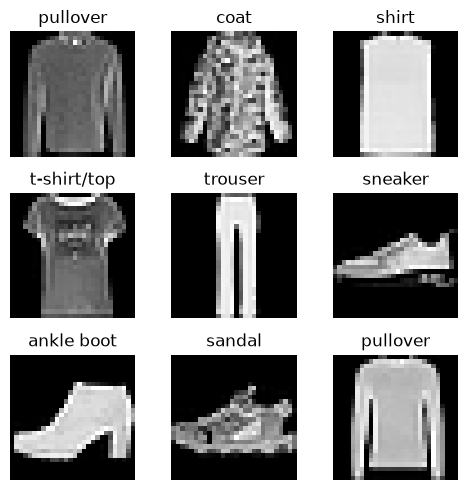

In [5]:
# Define class names
fashion_names = {
    0: "t-shirt/top",
    1: "trouser",
    2: "pullover",
    3: "dress",
    4: "coat",
    5: "sandal",
    6: "shirt",
    7: "sneaker",
    8: "bag",
    9: "ankle boot"
}

# Visualise 
n = 3

fig, ax = plt.subplots(n, n, figsize = (5, 5))

for i in range(n):
    for j in range(n):
        image, label = fashion_train[i * n + j] 
        image_np = image.numpy().squeeze() # Convert image tensor to numpy array
        ax[i, j].imshow(image_np, cmap = "gray")
        ax[i, j].axis("off")
        ax[i, j].set_title(fashion_names[label])
plt.tight_layout()
plt.show()

**Dataloader** (for more efficient processing)

Shuffling doesn't really matter for the validation and test set. Only changes the order of things, but if you take the average it should be the same regardless of order

In [3]:
# Batch_size of 64 is used for training, validation and testing. 64 was not tuned but chosen as a reasonable starting point based on conventional practices.

batch_size = 64

fashion_train_loader = DataLoader(fashion_train, batch_size = batch_size, shuffle = True)
fashion_validation_loader = DataLoader(fashion_validation, batch_size = batch_size, shuffle = False)
fashion_test_loader = DataLoader(fashion_test, batch_size = batch_size, shuffle = False)

In [7]:
print(f"Number of batches in the training DataLoader: {len(fashion_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(fashion_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(fashion_test_loader)}")
images, labels = next(iter(fashion_train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 844
Number of batches in the validation DataLoader: 94
Number of batches in the test DataLoader: 157
Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Image data type: torch.float32
Pixel range: 0.0 1.0


### Model building

NOTES
* The default values set for the parameters were taken from the values from the tutorials and have no particularily significant reasoning behind them and are treated as initial values from which we later explore choices for the architecture with experimental runs.

In [4]:
# Hardware device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [5]:
# Class to create a neural network
class NeuralNetwork(nn.Module):
    def __init__(self, 
            model_type = "MLP", # type of model to create (MLP or CNN)
            in_channels = 1, # number of input channels (1 for grayscale images)
            image_size = 28, # size of the input image (28x28 for FashionMNIST)
            hidden_dims = [128, 64], # list of hidden dimensions for MLP
            cnn_channels = [16, 32], # list of convolutional channels for CNN
            kernel_size=3, #size of the convolutional kernel for CNN
            pool_size=2, #size of the pooling kernel for CNN
            stride=2, #stride for pooling for CNN
            activation=nn.ReLU, #activation function
            initialization=None, #weight initialization method
            dropout=0.0 #dropout rate
            ):   
         
        super().__init__() 
        self.model_type = model_type

        #---------------Build the MLP model---------------
        if model_type == "MLP":
            # Create the layers 
            layers = [nn.Flatten()]
            input_size = in_channels * image_size * image_size # Amount of pixels we have

            for hidden_size in hidden_dims:
                layers.append(nn.Linear(input_size, hidden_size))
                layers.append(activation())

                if dropout > 0:
                    layers.append(nn.Dropout(dropout))

                input_size = hidden_size # Change input size, so each layer connects to the next one

            layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)

            # Combine all our layers into a network
            self.network = nn.Sequential(*layers)# asterisk transforms the list into positional arguments

        #---------------Build the CNN model---------------
        elif model_type == "CNN":
            # Convolutional layers
            feature_layers = []
            current_size = image_size
            for conv_block in range(len(cnn_channels)): # we iterate over the number of convolutional blocks
                in_ch = in_channels if conv_block == 0 else cnn_channels[conv_block - 1]#if conv_block == 0, we use the input channels, otherwise we use the output channels of the previous layer
                out_ch = cnn_channels[conv_block]
                
                feature_layers.append(nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size // 2))# We use padding to keep the output size the same as the input size
                feature_layers.append(activation())
                feature_layers.append(nn.MaxPool2d(kernel_size=pool_size, stride=stride))# We use max pooling to reduce the size of the feature maps
                if dropout > 0:
                    feature_layers.append(nn.Dropout(dropout))

                # MaxPool2d reduces spatial size by stride factor
                current_size = current_size // stride
            # Combine all our layers into a feature extractor
            self.features = nn.Sequential(*feature_layers)

            #Linear Layers
            classifier_layers = [nn.Flatten()]
            input_size = cnn_channels[-1] * current_size * current_size # Last convolutional layer output channels * spatial size of the feature maps
            for hidden_size in hidden_dims:
                classifier_layers.append(nn.Linear(input_size, hidden_size))
                classifier_layers.append(activation())
            
                if dropout > 0:
                    classifier_layers.append(nn.Dropout(dropout))
            
                input_size = hidden_size   

            classifier_layers.append(nn.Linear(input_size, 10)) # Last layer (output: 10, because we have 10 classes)
            # Combine all our layers into a classifier
            self.classifier = nn.Sequential(*classifier_layers)

        # Initialize weights
        if initialization is not None: # Doublecheck that Initilization = None in the baseline model is what the lecturer explained in class
            self.parameter_initializations(initialization)

    def forward(self, x):
        if self.model_type == "MLP":
            return self.network(x)

        elif self.model_type == "CNN":
            x = self.features(x)
            logits = self.classifier(x)
            return logits

    def parameter_initializations(self, name):

        for layer in self.modules():
            if isinstance(layer, (nn.Linear, nn.Conv2d)):

                match name:
                    case "uniform": 
                        nn.init.uniform_(layer.weight)
                    case "xavier":
                        nn.init.xavier_uniform_(layer.weight)
                    case "kaiming":
                        nn.init.kaiming_uniform_(layer.weight, a = 0, mode = "fan_in", nonlinearity = "relu")
                    case "zero": 
                        nn.init.zeros_(layer.weight)
                    case "one":
                        nn.init.ones_(layer.weight)
                    case "normal":
                        nn.init.normal_(layer.weight, mean = 0.0, std = 1)


In [6]:
# Function to count the number of parameters in a model, for comparison purposes whilst exploring different architectures and hyperparameters.

def count_parameters(model, verbose=True):
    total_params = sum(p.numel() for p in model.parameters())
    if verbose:
        print(f"Total Parameters: {total_params:,}")
    return total_params

In [7]:
criterion = nn.CrossEntropyLoss()

def run_experiment(params, train = fashion_train, validation = fashion_validation, 
                   test = fashion_test, plotting = False, seed = 67):
    # 1. Force identical random states for experimental runs (for reproducibility).
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
    # Create DataLoaders
    train_loader = DataLoader(train, batch_size = params["batch_size"], shuffle = True)
    validation_loader = DataLoader(validation, batch_size = params["batch_size"], shuffle = False)
    test_loader = DataLoader(test, batch_size = params["batch_size"], shuffle = False)

    # Create the model
    model_params = {key: value for key, value in params.items() 
                    if key not in ("epochs", "batch_size", "optimizer", 
                                   "learning_rate", "momentum", "weight_decay")}
    model = NeuralNetwork(**model_params).to(device)

    # Create optimizer, possibly redundant? We create the optimizer here but also have a class function for it, remove one of two.
    optimizer_name = {
        "SGD": optim.SGD,
        "Adam": optim.Adam,
        "AdamW": optim.AdamW
    }

    args = {"lr": params["learning_rate"], "weight_decay": params["weight_decay"]}

    if params["optimizer"] == "SGD": 
        args["momentum"] = params["momentum"]

    optimizer = optimizer_name[params["optimizer"]](model.parameters(), **args)

    # Store losses and accuracies for each epoch
    history = {
        "train_loss": [0.0] * params["epochs"],
        "val_loss": [0.0] * params["epochs"],
        "train_acc": [0.0] * params["epochs"],
        "val_acc": [0.0] * params["epochs"]
        }

    best_val_loss = np.inf
    best_model_state = None

    for epoch in range(params["epochs"]):
        model.train()


        #---------- Training Phase ----------
        train_loss_total = 0.0
        train_correct_total = 0
        train_total = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad() # Clear gradients from the previous step
            
            # Forward pass
            outputs = model(inputs) # Make predictions
            loss = criterion(outputs, labels) # Calculate loss

            # Backward pass 
            loss.backward()  # Calculate gradients
            optimizer.step() # Update weights

            # Training performance
            train_loss_total += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs.data, 1) # Get the index of the max log-probability
            train_correct_total += (predicted == labels).sum().item() # Count the number of correct predictions
            train_total += labels.size(0)

        # Average training loss for this epoch
        history["train_loss"][epoch] = train_loss_total / train_total

        # Average training accuracy for this epoch
        history["train_acc"][epoch] = 100.0 * train_correct_total / train_total

        #---------- Validation Phase ----------
        #Validate after each epoch
        model.eval()
        val_loss_total = 0.0
        val_correct_total = 0
        val_total = 0
        with torch.no_grad():
            for inputs, labels in validation_loader:
                inputs, labels = inputs.to(device), labels.to(device)

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss_total += loss.item() * labels.size(0)

                _, predicted = torch.max(outputs.data, 1)
                val_correct_total += (predicted == labels).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_total / val_total        
        history["val_loss"][epoch] = val_loss
        history["val_acc"][epoch] = 100.0 * val_correct_total / val_total

        # Save model with lowest validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            # Saves model's parameters (cloning tensor onto CPU memory)
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    # Get the best model
    model.load_state_dict(best_model_state)

    #---------- Test Phase ----------
    # Evaluate performance on unseen data (test set)
    test_loss_total = 0.0
    test_correct_total = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            test_loss_total += loss.item() * labels.size(0)

            _, predicted = torch.max(outputs.data, 1)
            test_correct_total += (predicted == labels).sum().item()
            test_total += labels.size(0)

    test_loss = test_loss_total / test_total
    # Calculate test accuracy
    test_acc = 100.0 * test_correct_total / test_total

    history["test_acc"] = test_acc

    # Calculate best validation accuracy (from the epoch with lowest val loss)
    best_val_acc = history["val_acc"][np.argmin(history["val_loss"])]


    if plotting:
        epochs_range = range(1, params["epochs"] + 1)
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

        # Loss Plot
        ax1.plot(epochs_range, history["train_loss"], marker="o", label="Train Loss")
        ax1.plot(epochs_range, history["val_loss"], marker="o", label="Validation Loss")
        ax1.set_title("Cross-Entropy Loss")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Loss")
        ax1.legend()
        ax1.grid(True) 

        # Accuracy Plot
        ax2.plot(epochs_range, history["train_acc"], marker="o", label="Train Accuracy")
        ax2.plot(epochs_range, history["val_acc"], marker="o", label="Validation Accuracy")
        ax2.set_title("Classification Accuracy (%)")
        ax2.set_xlabel("Epoch")
        ax2.set_ylabel("Accuracy (%)")
        ax2.legend()
        ax2.grid(True) 

        plt.tight_layout()
        plt.show()
    
    return model, history, best_val_loss, best_val_acc, test_loss, test_acc

## Parameters and Testing

Parameters

* Model and architecture
    * model_type: "MLP" or "CNN"
    * hidden_dims: Any list of integers
    * channels
    * kernel_size 
* Activation
    * Can be nn.ReLU, nn.LeakyReLU, nn.GELU
    * Also more options (see Session 3 slide 10) nn.Signmoid, nn.Tahn, nn.PReLU, nn.Softplus, nn.SiLU, nn.ELU, nn.SELU 
* Optimizer
    * optimizer: "SGD", "Adam", "AdamW"
    * learning_rate
    * momentum
* Regularization
    * dropout
* Training
    * epochs
    * batch_size


In [19]:
params1 = {
    # Model and architecture
    "model_type": "CNN", # "MLP" or "CNN"
    "hidden_dims": [128, 64], 
    "cnn_channels": [16, 32], # Only for CNNs
    "kernel_size": 3, # Only for CNNs
    "pool_size": 2, # Only for CNNs
    "stride": 2, # Only for CNNs

    # Activation
    "activation": nn.ReLU, 

    # Weight initialization
    "initialization": None, # Optional

    # Optimizer
    "optimizer": "AdamW",
    "learning_rate": 0.001, 
    "weight_decay": 0.0, # Optional, regularization
    "momentum": 0.9, # Only if optimizer = "SGD"

    # Regularization
    "dropout": 0.0, # Optional

    # Training
    "epochs": 30,
    "batch_size": 64
}

--- MLP ---


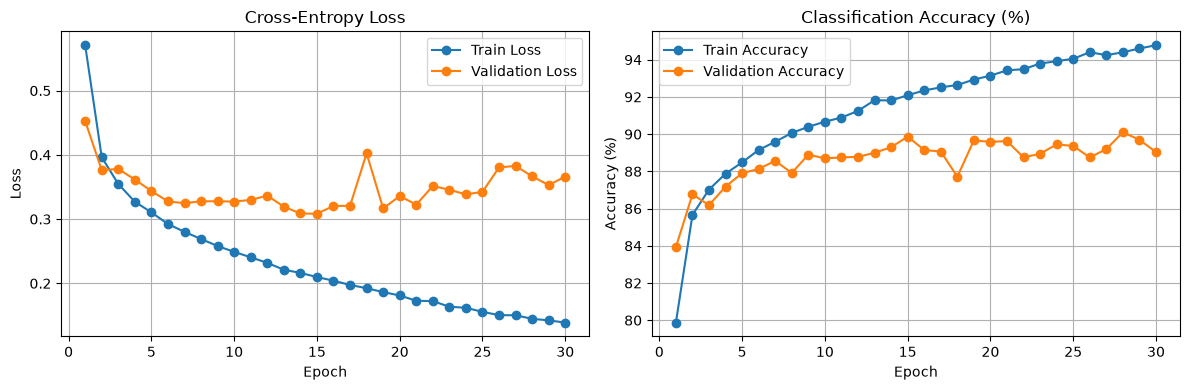


Experiment 1 Results:MLP
NeuralNetwork(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Best Validation Loss: 0.3083|Best Validation Accuracy: 89.87%
Test Loss: 0.3300 | Test Accuracy: 88.56%
--- CNN ---


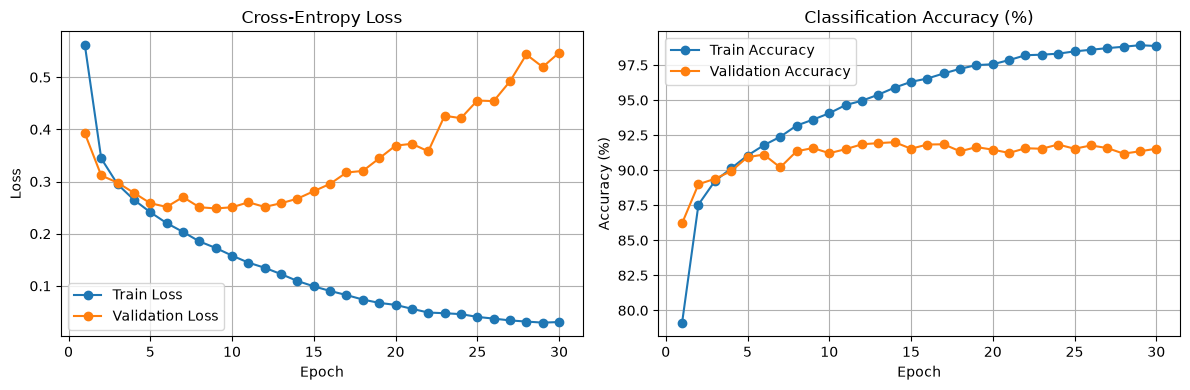


Experiment 1 Results:CNN
NeuralNetwork(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)
Best Validation Loss: 0.2484|Best Validation Accuracy: 91.58%
Test Loss: 0.2595 | Test Accuracy: 90.93%


In [21]:
for model_type in ["MLP", "CNN"]:
    print(f"--- {model_type} ---")                         # printed before the figure, so each figure is labelled
    params = {**params1, "model_type": model_type}         # copy of params1 with only the model type changed
    model, history, best_val_loss, best_val_acc, test_loss, test_acc = run_experiment(params, plotting=True)
    print(f"\nExperiment 1 Results:{model_type}")
    print(model)
    print(f"Best Validation Loss: {best_val_loss:.4f}|Best Validation Accuracy: {best_val_acc:.2f}%")
    print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%")

To choose the number of epochs for the later experiments, we first trained the base MLP and CNN (AdamW, learning rate 0.001, batch size 64) for 30 epochs and monitored the validation loss. More epochs increase computation time and, once the validation loss starts rising, lead to overfitting. The validation loss of the MLP reached its minimum at around epoch 15, and that of the CNN at around epoch 10, after which it increased while the training loss kept falling. We use 15 epochs for both models, so that the comparison between them is fair and the slower MLP is not cut off. Because the weights of the epoch with the lowest validation loss are kept, the extra epochs cost only computation time, not accuracy.

The number of epochs needed also depends on the optimizer and the learning rate: a small learning rate (for example SGD with 0.001) is still improving after 30 epochs with the loss bottoming out between 50 to 60 epochs. A fixed budget of 15 epochs thus penalizes slowly converging configurations. We take this into account when interpreting the results.

### We use parameter grids, in order to find the effect of each Hyperparameter

In [ ]:
# 1. Define base parameters that remain constant
base_params = {
    "model_type": "MLP",
    "in_channels": 1,
    "image_size": 28,
    "hidden_dims": [128, 64],
    "activation": nn.ReLU,
    "initialization": None,
    "weight_decay": 0.0,
    "dropout": 0.0,
    "epochs": 15,      # We should keep epochs low during grid search to save time
    "batch_size": 64
}

# 2. Define the parameters you want to test
lr_grid = {
    "SGD":   [0.1, 0.03, 0.01, 0.003, 0.001],
    "AdamW": [0.1, 0.01, 0.003, 0.001, 0.0003, 0.0001],
    "Adam":  [0.1, 0.01, 0.001]
}
experiment_results = []

# 3. Loop through all possible combinations

for opt, lrs in lr_grid.items():
    for lr in lrs:
        print(f"Testing -> Optimizer: {opt} | LR: {lr}")
    
        # Clone base params and inject the current test variables
        current_params = base_params.copy()
        current_params["learning_rate"] = lr
        current_params["optimizer"] = opt
    
        # Handle the momentum edge case (Adam doesn't use standard momentum)
        current_params["momentum"] = 0.9 if opt == "SGD" else 0.0
    

        # We set plotting = False to prevent plot generation.
        model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(
        current_params, 
        plotting=False
        )
    
        # We save the metrics
        experiment_results.append({
            "Optimizer": opt,
            "LR": lr,
            "Dropout": base_params["dropout"],
            "Val Loss": round(val_loss, 4),
            "Val Acc (%)": round(val_acc, 2),
            "Test Acc (%)": round(test_acc, 2)
        })

# 4. Display the results neatly
results_df = pd.DataFrame(experiment_results)
# Sort by highest validation accuracy
results_df = results_df.sort_values(by="Val Acc (%)", ascending=False).reset_index(drop=True)
display(results_df)

Testing -> Optimizer: SGD | LR: 0.1
Testing -> Optimizer: SGD | LR: 0.03
Testing -> Optimizer: SGD | LR: 0.01
Testing -> Optimizer: SGD | LR: 0.003
Testing -> Optimizer: SGD | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.1
Testing -> Optimizer: AdamW | LR: 0.01
Testing -> Optimizer: AdamW | LR: 0.003
Testing -> Optimizer: AdamW | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.0003
Testing -> Optimizer: AdamW | LR: 0.0001
Testing -> Optimizer: Adam | LR: 0.1
Testing -> Optimizer: Adam | LR: 0.01
Testing -> Optimizer: Adam | LR: 0.001


,Optimizer,LR,Dropout,Val Loss,Val Acc (%),Test Acc (%)
0,AdamW,0.0010,0.0,0.3083,89.87,88.56
1,Adam,0.0010,0.0,0.3083,89.87,88.56
2,SGD,0.0300,0.0,0.3144,89.13,88.36
3,SGD,0.0100,0.0,0.3199,88.78,88.26
4,AdamW,0.0030,0.0,0.3266,88.72,87.70
5,AdamW,0.0003,0.0,0.3281,87.97,87.74
6,SGD,0.0030,0.0,0.3487,87.65,87.00
7,AdamW,0.0100,0.0,0.3596,87.35,86.74
8,Adam,0.0100,0.0,0.3596,87.35,86.74
9,SGD,0.1000,0.0,0.3619,87.18,86.43


In [18]:
# 1. Define base parameters that remain constant
base_params = {
    "model_type": "CNN",
    "in_channels": 1,
    "image_size": 28,
    "hidden_dims": [128, 64],
    "activation": nn.ReLU,
    "initialization": None,
    "weight_decay": 0.0,
    "dropout": 0.0,
    "epochs": 15,      # We should keep epochs low during grid search to save time
    "batch_size": 64
}

# 2. Define the parameters you want to test
lr_grid = {
    "SGD":   [0.1, 0.03, 0.01, 0.003, 0.001],
    "AdamW": [0.1, 0.01, 0.003, 0.001, 0.0003, 0.0001],
    "Adam":  [0.1, 0.01, 0.001]
}
experiment_results = []

# 3. Loop through all possible combinations

for opt, lrs in lr_grid.items():
    for lr in lrs:
        print(f"Testing -> Optimizer: {opt} | LR: {lr}")
    
        # Clone base params and inject the current test variables
        current_params = base_params.copy()
        current_params["learning_rate"] = lr
        current_params["optimizer"] = opt
    
        # Handle the momentum edge case (Adam doesn't use standard momentum)
        current_params["momentum"] = 0.9 if opt == "SGD" else 0.0
    

        # We set plotting = False to prevent plot generation.
        model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(
        current_params, 
        plotting=False
        )
    
        # We save the metrics
        experiment_results.append({
            "Optimizer": opt,
            "LR": lr,
            "Dropout": base_params["dropout"],
            "Val Loss": round(val_loss, 4),
            "Val Acc (%)": round(val_acc, 2),
            "Test Acc (%)": round(test_acc, 2)
        })

# 4. Display the results neatly
results_df = pd.DataFrame(experiment_results)
# Sort by highest validation accuracy
results_df = results_df.sort_values(by="Val Acc (%)", ascending=False).reset_index(drop=True)
display(results_df)

Testing -> Optimizer: SGD | LR: 0.1
Testing -> Optimizer: SGD | LR: 0.03
Testing -> Optimizer: SGD | LR: 0.01
Testing -> Optimizer: SGD | LR: 0.003
Testing -> Optimizer: SGD | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.1
Testing -> Optimizer: AdamW | LR: 0.01
Testing -> Optimizer: AdamW | LR: 0.003
Testing -> Optimizer: AdamW | LR: 0.001
Testing -> Optimizer: AdamW | LR: 0.0003
Testing -> Optimizer: AdamW | LR: 0.0001
Testing -> Optimizer: Adam | LR: 0.1
Testing -> Optimizer: Adam | LR: 0.01
Testing -> Optimizer: Adam | LR: 0.001


,Optimizer,LR,Dropout,Val Loss,Val Acc (%),Test Acc (%)
0,Adam,0.0010,0.0,0.2459,91.72,91.17
1,AdamW,0.0010,0.0,0.2513,91.48,91.13
2,AdamW,0.0030,0.0,0.2407,91.28,90.49
3,SGD,0.0100,0.0,0.2472,91.15,91.07
4,SGD,0.0300,0.0,0.2533,91.08,90.46
5,AdamW,0.0003,0.0,0.2642,91.03,89.90
6,AdamW,0.0100,0.0,0.2836,90.37,89.39
7,SGD,0.0030,0.0,0.2913,89.53,89.25
8,Adam,0.0100,0.0,0.2867,89.50,88.72
9,SGD,0.1000,0.0,0.3286,89.20,88.02


Here we start our experiments by comparing combinations of optimizers and learning rates for both MLP and CNN. Through some initial exploration and reading, the most important choices in neural network designs are commonly regarded as the choices of optimizer and learning rates as well as the architecture choices (i.e. deeper or wider neural networks). For architecture, greater depth/width increases the capacity to learn which may improve the fit but could also lead to overfitting. Whether it would be best to first explore architecture or the learning rates/optimizers is a bit difficult to establish. A bad learning rate could make good architecture look terrible and a poor architecture could make a well tuned learning rate look terrible. By looking at a grid of optimizer and learning rate combinations first with a base architecture however we hope to at least gain some insight into roughly what values of learning rates are ideal for the different optimizers and how well they actually perform. We see that AdamW and Adam with weight decay set to 0 generally amount to nearly identical results, consistent with what we know about the optimizers (they are the same algorithm when weight_decay is set to 0). Furthermore with a learning rate of 0.1 Adam/AdamW in CNN collapse to what amounts to be random guessing (10 classes and 10% validation accuracy)

We can see that the CNN outperforms the MLP in nearly all combinations by roughly 1.5-3 percentage points in validation accuracy. The only exceptions are Adam/AdamW with learning rates of 0.1 where CNN collapses to 10% validation accuracy whilst MLP stays around 53%. The best learning rate for AdamW is 0.001 for both models, whereas SGD needs a higher rate in the range of 0.01-0.03.This is because Adam/AdamW divide the gradient by an estimate of its current size so each weight moves the size of the lr per step whereas with SGD the step is scaled with the gradients which are usually small. You can see this by how SGD with a learning rate of 0.001 is the worst configuration in both models because of this smaller effective step size. This particular configuration leads to an under-trained model with the limit of 15 epochs, which has also been shown in the figure above with epoch of 100 for SGD reaching a similar accuracy as AdamW much later.

The differences between the top configurations are small. For the CNN, the best AdamW and SGD configurations reach 91.83% and 91.75% validation accuracy, and for the MLP the best two are less than one percentage point apart. With a single seed, gaps of this size could simply reflect the random weight initialization and the random order of the batches, so any conclusion about which configuration is best would hinge on one run. We therefore repeat the grid with two additional seeds (68 and 69) and compare the means and standard deviations over the three seeds, to see which configurations perform well consistently for this initial optimizer/learning rate configuration.

In [9]:
base_params = {
    "model_type": "CNN",
    "in_channels": 1,
    "image_size": 28,
    "hidden_dims": [128, 64],
    "activation": nn.ReLU,
    "initialization": None,
    "weight_decay": 0.0,
    "dropout": 0.0,
    "epochs": 15,
    "batch_size": 64
}

In [17]:
base_params = {
    "model_type": "CNN",
    "in_channels": 1,
    "image_size": 28,
    "hidden_dims": [128, 64],
    "activation": nn.ReLU,
    "initialization": None,
    "weight_decay": 0.0,
    "dropout": 0.0,
    "epochs": 15,
    "batch_size": 64
}

lr_grid = {
    "SGD":   [0.1, 0.03, 0.01, 0.003, 0.001],
    "AdamW": [0.01, 0.003, 0.001, 0.0003, 0.0001],
}
seeds = [67, 68, 69]

raw_results = []

for opt, lrs in lr_grid.items():
    for lr in lrs:
        for seed in seeds:
            print(f"Testing -> Optimizer: {opt} | LR: {lr} | Seed: {seed}")

            current_params = base_params.copy()
            current_params["learning_rate"] = lr
            current_params["optimizer"] = opt
            current_params["momentum"] = 0.9 if opt == "SGD" else 0.0

            model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(
                current_params, plotting=False, seed=seed
            )

            raw_results.append({
                "Optimizer": opt,
                "LR": lr,
                "Seed": seed,
                "Val Loss": val_loss,
                "Val Acc (%)": val_acc,
                "Test Acc (%)": test_acc
            })

# One row per run
raw_df = pd.DataFrame(raw_results)
# raw_df.to_csv("stage1_cnn_lr_raw.csv", index=False) unhashtag if we wanna store these values.

# One row per configuration: mean and standard deviation over the seeds
summary_df = (raw_df.groupby(["Optimizer", "LR"])
              .agg(val_acc_mean=("Val Acc (%)", "mean"),
                   val_acc_std=("Val Acc (%)", "std"),
                   val_loss_mean=("Val Loss", "mean"),
                   val_loss_std=("Val Loss", "std"))
              .round(3)
              .sort_values("val_acc_mean", ascending=False)
              .reset_index())
display(summary_df)
# summary_df.to_csv("stage1_cnn_lr_summary.csv", index=False) unhashtag if we wanna store these values.

Testing -> Optimizer: SGD | LR: 0.1 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.1 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.1 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.03 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.03 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.03 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.01 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.01 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.01 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.003 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.003 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.003 | Seed: 69
Testing -> Optimizer: SGD | LR: 0.001 | Seed: 67
Testing -> Optimizer: SGD | LR: 0.001 | Seed: 68
Testing -> Optimizer: SGD | LR: 0.001 | Seed: 69
Testing -> Optimizer: AdamW | LR: 0.01 | Seed: 67
Testing -> Optimizer: AdamW | LR: 0.01 | Seed: 68
Testing -> Optimizer: AdamW | LR: 0.01 | Seed: 69
Testing -> Optimizer: AdamW | LR: 0.003 | Seed: 67
Testing -> Optimizer: AdamW | LR: 0.003 | Seed: 68
Testing -> Optimizer: Ada

,Optimizer,LR,val_acc_mean,val_acc_std,val_loss_mean,val_loss_std
0,AdamW,0.0010,91.711,0.146,0.240,0.005
1,AdamW,0.0030,91.472,0.098,0.244,0.003
2,SGD,0.0100,91.472,0.151,0.244,0.002
3,AdamW,0.0003,91.017,0.173,0.259,0.002
4,SGD,0.0300,91.006,0.226,0.254,0.005
5,AdamW,0.0100,90.139,0.206,0.292,0.009
6,SGD,0.0030,89.994,0.217,0.287,0.003
7,SGD,0.1000,89.039,0.258,0.316,0.006
8,AdamW,0.0001,88.833,0.073,0.325,0.004
9,SGD,0.0010,87.517,0.100,0.356,0.007


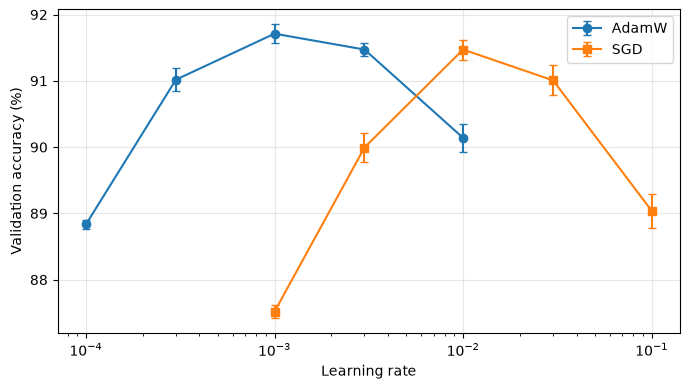

In [23]:
fig, ax = plt.subplots(figsize=(7, 4))
for opt, marker in [("AdamW", "o"), ("SGD", "s")]:
    d = summary_df[summary_df["Optimizer"] == opt].sort_values("LR")
    ax.errorbar(d["LR"], d["val_acc_mean"], yerr=d["val_acc_std"], marker=marker, capsize=3, label=opt)
ax.set_xscale("log")
ax.set_xlabel("Learning rate")
ax.set_ylabel("Validation accuracy (%)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("fig_lr_sweep.pdf")   # vector format stays sharp in the report
plt.show()

Averaged over three seeds (mean ± standard deviation of the validation accuracy), the best configuration is AdamW with learning rate 0.001 (91.71 ± 0.15%), followed by AdamW with 0.003 (91.47 ± 0.10%) and SGD with 0.01 (91.47 ± 0.15%). The gap between the best and the next two is 0.24 percentage points, only about 1.5-2 times the seed-to-seed standard deviation, and their validation losses are close (0.240, 0.244 and 0.244). With three seeds we therefore consider these configurations to perform similarly well, with AdamW 0.001 possibly slightly ahead. SGD with 0.03 (91.01 ± 0.23%) and AdamW with 0.0003 (91.02 ± 0.17%) are about 0.7 points below the best, and all other configurations are at least 1.5 points below it. AdamW is also less sensitive to the learning rate: its next two best configurations (0.003 and 0.0003) are both within 1 percentage point of its best, so every learning rate from 0.0003 to 0.003 works well. For SGD only 0.01 and 0.03 are within 1 point of its best, and the third best (0.003) is 1.5 points lower. Because of this robustness, and not because it is clearly better than SGD at its best learning rate, we use AdamW with a learning rate of 0.001 for the subsequent experiments.

We also use the seed to seed variation as a rough guideline for judging the sweeps that follow. It is not fully encompassing, since it is based on only three seeds and on the stage 1 setup, but the standard deviations give us an idea of how much a result can change between runs, so a configuration that wins in one run may not win in another and is then not conclusive. In the table the standard deviations of the validation accuracy run from 0.073 to 0.258, and the pooled standard deviation over all configurations (square the standard deviations, take the mean then take the square root of this value) is about 0.18. This is an estimate of the run to run standard deviation. For the sweeping experiments below however we compare one run to another run and as such this noise will add up. An estimate for the standard deviation of any comparison between runs then becomes the square root of ((0.18^2)*2), which comes out to roughly 0.25. Two standard deviations would then be 0.5, so for comparisons of validation accuracies we will take any difference below 0.5 as inconclusive and any difference above it as a reasonable indication of an actual effect. This is only a rough guideline given the three seeds and the limited setup.

In [12]:
def sweep_one(base, name, values):
    # Vary one hyperparameter at a time, keep the rest constant
    rows = []
    for value in values:
        params = base.copy()
        params[name] = value

        model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(params)

        rows.append({
            name: value.__name__ if isinstance(value, type) else value,  # shows ReLU instead of <class ...>
            "n_params": count_parameters(model, verbose=False), # To account for different architecture structures using more parameters
            "val_loss": round(val_loss, 4),
            "val_acc": round(val_acc, 2),
        })

    return pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)

In [14]:
# Winner of stage 1: AdamW, lr 0.001
base = {**base_params, "optimizer": "AdamW", "learning_rate": 0.001, "momentum": 0.0}

In [15]:
# Stage 2: Architecture MLP 
base = {**base_params, "model_type": "MLP", "optimizer": "AdamW", "learning_rate": 0.001, "momentum": 0.0}
res_head_depth = sweep_one(base, "hidden_dims", [[128], [128, 128], [128, 128, 128]])
display(res_head_depth)

,hidden_dims,n_params,val_loss,val_acc
0,"[128, 128]",118282,0.3109,89.02
1,[128],101770,0.3134,88.90
2,"[128, 128, 128]",134794,0.3101,88.75


[128, 128] seems to have the highest accuracy, however [128, 128, 128] has the lowest loss and in both cases the difference is quite minimal. This may point to the ranking inherently just potentially being noise given our previously established run to run noise threshold of 0.5. Any single choice of depth in this situation is defensible, however we will also look at CNN architecture as well as carrying over the configuration to CIFAR to consider and as such we hold off on making any clearcut choice for depth.

In [16]:
res_head_width = sweep_one(base, "hidden_dims", [[32, 32], [64, 64], [128, 128], [256, 256]])
display(res_head_width)

,hidden_dims,n_params,val_loss,val_acc
0,"[128, 128]",118282,0.3109,89.02
1,"[256, 256]",269322,0.3100,88.85
2,"[64, 64]",55050,0.3250,88.50
3,"[32, 32]",26506,0.3588,87.35


For MLP with two hidden layers, 128 nodes within each layer seems to perform best on accuracy, with 256 and 64 nodes performing slightly worse on accuracy but not conclusively so. In terms of loss, 256 actually performs slightly better. In both cases, the differences in the top 3 could again be noise rather than an actual sign of increased performance. 32 nodes however deviates roughly 1.67 percentage points from the ideal width and as such we hypothesize that this is an indication of too little width. One reason for this may be that 32 nodes are too few to preserve the information coming into the first layer of the 784 input pixels and as such the model may struggle to seperate the 10 classes.

In [17]:
# Winner of stage 2: Hidden dimensions [128, 128] for MLP 
base = {**base, "hidden_dims": [128, 128]}

In [18]:
# Stage 3: activation, initialization, dropout and weight decay for the MLP model
# Each factor is varied on its own around the same base (the Stage 2 winners).
sweeps = {
    "Activation":     ("activation",     [nn.ReLU, nn.LeakyReLU, nn.GELU, nn.SiLU]),
    "Initialization": ("initialization", [None, "xavier", "kaiming", "zero"]),   # None = PyTorch default
    "Dropout":        ("dropout",        [0.0, 0.1, 0.3, 0.5]),
    "Weight decay":   ("weight_decay",   [0.0, 1e-3, 1e-2, 1e-1]),               # AdamW, the base optimizer
}

tables = []
for factor, (name, values) in sweeps.items():
    print(f"Sweep: {factor}")
    res = sweep_one(base, name, values).rename(columns={name: "Setting"})
    res.insert(0, "Factor", factor)
    tables.append(res)

stage3_summary = pd.concat(tables, ignore_index=True)
stage3_summary["Setting"] = stage3_summary["Setting"].astype(str).replace("None", "default")
display(stage3_summary)

Sweep: Activation
Sweep: Initialization
Sweep: Dropout
Sweep: Weight decay


,Factor,Setting,n_params,val_loss,val_acc
0,Activation,LeakyReLU,118282,0.3180,89.30
1,Activation,GELU,118282,0.3001,89.30
2,Activation,ReLU,118282,0.3109,89.02
3,Activation,SiLU,118282,0.3090,89.02
4,Initialization,kaiming,118282,0.3112,89.53
5,Initialization,xavier,118282,0.3118,89.10
6,Initialization,default,118282,0.3109,89.02
7,Initialization,zero,118282,0.3336,88.90
8,Dropout,0.1,118282,0.3101,89.08
9,Dropout,0.0,118282,0.3109,89.02


The above table shows the activation, initialization and regularization sweeps for the MLP (base: AdamW with a learning rate of 0.001, two hidden layers of 128 nodes, ReLU, default initialization, no dropout and no weight decay). The activation functions span only 0.28 points (89.02-89.30%), which is within the run-to-run noise established in Stage 1 when comparing different seeds, so we do not rank them. Kaiming initialization is 0.51 points above the default (89.53% versus 89.02%) and 0.43 above the next best (Xavier, 89.10%), which is at the edge of the noise and of interest but not entirely conclusive yet. Dropout of 0.1 is indistinguishable from no dropout (89.08% versus 89.02%, loss 0.3101 versus 0.3109), whereas higher values hurt: 0.3 lowers the accuracy by 0.34 points and 0.5 by 0.99 points (loss 0.3408). Weight decay of 0.001 is slightly above no weight decay (89.38% versus 89.02%), but larger values lower the accuracy again (88.88% and 88.65%), so we see no clear benefit in weight decay.

A possible explanation for the negative effect of dropout is that this MLP has little redundancy: its first layer already has to compress 784 pixels into 128 nodes (a width of 32 was too small in Stage 2), so removing units loses information the network needs. In addition, regularization slows convergence, so the 15-epoch budget may be too short for the regularized models.

We now proceed with the sweep analysis on the CNN model.

In [27]:
# Stage 2: Architecture CNN
base = {**base_params, "model_type": "CNN", "optimizer": "AdamW", "learning_rate": 0.001, "momentum": 0.0}
res_head_depth = sweep_one(base, "hidden_dims", [[128], [128, 128], [128, 128, 128]])
display(res_head_depth)

,hidden_dims,n_params,val_loss,val_acc
0,[128],206922,0.2426,91.67
1,"[128, 128, 128]",239946,0.2447,91.67
2,"[128, 128]",223434,0.2435,91.23


For the CNN, the number of hidden layers in the fully connected head has no measurable effect on the validation accuracy. One, two and three layers of 128 nodes give 91.67%, 91.23% and 91.67%, a spread of 0.44 points, which is about the size of the run-to-run noise established in Stage 1. The ordering is not monotonic (two layers is the lowest), and the validation losses are nearly identical (0.2426, 0.2435 and 0.2447), so we do not rank them. A possible explanation is that the convolutional layers already extract the relevant features, so the head is not the bottleneck.

In [20]:
res_head_width = sweep_one(base, "hidden_dims", [[32, 32], [64, 64], [128, 128], [256, 256]])
display(res_head_width)

,hidden_dims,n_params,val_loss,val_acc
0,"[64, 64]",110026,0.2392,91.88
1,"[32, 32]",56394,0.2579,91.53
2,"[128, 128]",223434,0.2410,91.47
3,"[256, 256]",474826,0.2416,91.27


The width of the two hidden layers in the head also has little effect for the CNN: 32, 64, 128 and 256 nodes give 91.53%, 91.88%, 91.47% and 91.27% validation accuracy, a spread of 0.61 points, without a trend (the largest head, with 475k parameters, is the lowest). Only the validation loss of the narrowest head is somewhat higher (0.2579 versus 0.239-0.242). This contrasts with the MLP, where 32 nodes per layer lowered the accuracy by 1.7 points. A possible explanation is that the convolutional layers already extract the relevant features, so even a narrow head can separate the classes, whereas the MLP head has to compress the raw pixels like we previously mentioned.

In [21]:
res_conv_depth = sweep_one(base, "cnn_channels", [[32], [32, 32], [32, 32, 32]])
display(res_conv_depth)

,cnn_channels,n_params,val_loss,val_acc
0,"[32, 32]",219306,0.2273,91.93
1,"[32, 32, 32]",64714,0.2445,91.62
2,[32],812170,0.2461,91.43


The number of convolutional block also only has a small effect on the CNN: one, two and three blocks give 91.43%, 91.93% and 91.62% validation accuracy, a spread of 0.50 points without a monotonic trend (one block is the worst and two blocks the best). Two blocks also has the lowest validation loss (0.2273 versus 0.2445 and 0.2461), but with a single run we do not consider this conclusive.

In [22]:
res_conv_width = sweep_one(base, "cnn_channels", [[8, 8], [16, 16], [32, 32], [64, 64]])
display(res_conv_width)

,cnn_channels,n_params,val_loss,val_acc
0,"[64, 64]",448010,0.2239,91.88
1,"[32, 32]",219306,0.2374,91.57
2,"[16, 16]",111866,0.2460,91.35
3,"[8, 8]",59874,0.2607,90.88


The number of channels per convolutional layer is the only architecture factor so far with a consistent effect on the CNN. Validation accuracy rises monotonically with width, from 90.88% with 8 channels to 91.88% with 64 channels (a spread of 1.0 point), and the validation loss falls at every step (from 0.2607 to 0.2239). Each single step is within the run-to-run noise we previously assessed in stage 1, but the monotonic trend in both measures and the total change are larger than it. The effect is not simply a matter of model size, because the number of parameters in the fully connected head did not matter in the previous sweeps. A possible explanation is that the number of filters limits how many distinct patterns in the images the convolutional layers can detect, so very few filters (8) are limited in how many patterns the convolutional layers may find.

In [26]:
res_kernel = sweep_one(base, "kernel_size", [3, 5, 7])
display(res_kernel)

,kernel_size,n_params,val_loss,val_acc
0,3,429258,0.2369,91.80
1,7,512458,0.2491,91.60
2,5,462538,0.2366,91.53


Kernel size did not seem to significantly influence the effect on CNN. Kernels of sizes 3, 5 and 7 had validation accuracies of 91.80%, 91.53% and 91.60% respectively. The spread was 0.27 point, well within the previously established noise from stage 1 and the decrease in accuracy also is not monotonic.

Discussion: We use monotonicity as argument for inconclusiveness, but there is a change that the peak value for any hyperparameter lies between values tested. As such the increase followed by a decrease behaviour we have observed in several hyperparameters would not be inconclusive. Instead treat it as potential evidence for inconclusivity when combined with the previously observed fact of noise inherent in the running of these models from seed to seed.

In [ ]:
# Update base with the winners of stage 2 (fill in from the tables above)
base = {**base,
        "hidden_dims": [64],     # <- winner from the head tables, we combine the winner of depth and width sweeps so 1 hidden layer of 64 nodes.
        "cnn_channels": [64, 64],     # <- winner from the conv tables
        "kernel_size": 3}             # <- winner from res_kernel

In [29]:
# Stage 3: activation, initialization, dropout and weight decay for CNN
# Each factor is varied on its own around the same base (the Stage 2 winners).
sweeps = {
    "Activation":     ("activation",     [nn.ReLU, nn.LeakyReLU, nn.GELU, nn.SiLU]),
    "Initialization": ("initialization", [None, "xavier", "kaiming", "zero"]),   # None = PyTorch default
    "Dropout":        ("dropout",        [0.0, 0.1, 0.3, 0.5]),
    "Weight decay":   ("weight_decay",   [0.0, 1e-3, 1e-2, 1e-1]),               # AdamW, the base optimizer
}

tables = []
for factor, (name, values) in sweeps.items():
    print(f"Sweep: {factor}")
    res = sweep_one(base, name, values).rename(columns={name: "Setting"})
    res.insert(0, "Factor", factor)
    tables.append(res)

stage3_summary = pd.concat(tables, ignore_index=True)
stage3_summary["Setting"] = stage3_summary["Setting"].astype(str).replace("None", "default")
display(stage3_summary)

Sweep: Activation


Sweep: Initialization
Sweep: Dropout
Sweep: Weight decay


,Factor,Setting,n_params,val_loss,val_acc
0,Activation,LeakyReLU,238986,0.2372,91.98
1,Activation,ReLU,238986,0.2396,91.85
2,Activation,SiLU,238986,0.2392,91.62
3,Activation,GELU,238986,0.2367,91.53
4,Initialization,xavier,238986,0.2334,92.38
5,Initialization,kaiming,238986,0.2407,92.03
6,Initialization,default,238986,0.2366,91.97
7,Initialization,zero,238986,2.3026,10.35
8,Dropout,0.1,238986,0.2224,92.23
9,Dropout,0.3,238986,0.2164,92.23


Above are the results of the activation, initialization and regularization sweeps for the CNN (a single hidden layer of 64 nodes, two convolutional layers of 64 channels, kernel size 3, AdamW with a learning rate of 0.001). Once again activation seems inconclusive, with a spread of 0.45 points between LeakyReLU (91.98%) and GELU (91.53%), below the 0.5 threshold. For initialization, xavier has the highest validation accuracy (92.38%), but it is only 0.35 points above kaiming and 0.41 above the default, so we cannot rank the three. Zero initialization collapses to what amounts to random guessing (10.35% validation accuracy on 10 classes), which contrasts with the MLP, where zero initialization still reached 88.90%. For dropout, the values 0, 0.1 and 0.3 lie within 0.28 points of each other (91.95-92.23%), and dropout of 0.5 is the lowest (91.57%), 0.38 below no dropout. This is the same direction as in the MLP, but much milder there: 0.5 lowered the accuracy of the MLP by 0.99 points. We hypothesize that the CNN has many more units than the MLP, and dropout is also applied after every convolutional block, so there is more redundancy between the nodes and removing a share of them costs less information than it did in the MLP. Weight decay gives the clearest result so far: a decay of 0.1 reaches 92.63%, 0.85 points above the second best (0.001, 91.78%) and 0.90 above no weight decay, above the 0.5 threshold, and with a clearly lower validation loss (0.2215 versus 0.2388).

Through the previous experiments we have observed the behaviour of various hyperparameters with regards to validation accuracy. The natural next step would be to take the best 3 configurations to assess how well they generalize to a new dataset, namely the CIFAR data. However, as we saw for several choices of hyperparameters, the best configurations are essentially ties, because the differences in validation accuracy are relatively small compared to the noise we observed in stage 1 when comparing seed to seed runs. Simply taking the three best performing configurations could therefore amount to mostly picking noise, and would give us little to compare in terms of generalization. Instead we choose 3 configurations for both the MLP and the CNN, based on the validation results, that differ from each other in only one or two hyperparameters, so that a difference on CIFAR can be linked to those hyperparameters, even if they are not the absolute best models. To see whether performance carries over, we also report the Fashion-MNIST results of the same configurations.

### CIFAR

In [ ]:
# Load CIFAR-10 using the exact same transform logic as FashionMNIST
transform_cifar = v2.Compose([
    v2.ToImage(), 
    v2.ToDtype(torch.float32, scale=True)
])

cifar_train_all = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=transform_cifar
)

cifar_test = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=transform_cifar
)

# 90/10 Train/Validation Split using the same group seed
train_size = int(0.9 * len(cifar_train_all))
validation_size = len(cifar_train_all) - train_size

cifar_train, cifar_validation = random_split(
    cifar_train_all,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(67)
)

In [17]:
cifar_base = {**base_params, "model_type": "MLP", "optimizer": "AdamW", "learning_rate": 0.001,
              "momentum": 0.0, "epochs": 15}
cnn_1 = {**cifar_base, "model_type": "CNN", "hidden_dims": [64], "cnn_channels": [64, 64],
         "kernel_size": 3, "dropout": 0.1, "weight_decay": 0.1}

configs = {
    "MLP-1": {**cifar_base, "hidden_dims": [128, 128]}, # The basic MLP model
    "MLP-2": {**cifar_base, "hidden_dims": [512, 512]}, # A wider MLP model with more hidden units
    "MLP-3": {**cifar_base, "hidden_dims": [128, 128], "dropout": 0.3}, # Dropout reduced validation accuracy, but perhaps it will help on CIFAR-10.
    "CNN-1": cnn_1, # A combination of the best configuration from the CNN sweeps.
    "CNN-2": {**cnn_1, "cnn_channels": [64, 64, 64]}, # More depth on the convolutional side, tied for FASHION but may improve CIFAR.
    "CNN-3": {**cifar_base, "model_type": "CNN", "hidden_dims": [128, 64], "cnn_channels": [16, 32],
              "kernel_size": 3}, # The initial starting point for CNNs, untuned to see if it can beat the tuned CNN-1 on CIFAR-10.
}

data = {"Fashion": (fashion_train, fashion_validation, fashion_test, 1, 28),
        "CIFAR-10": (cifar_train, cifar_validation, cifar_test, 3, 32)}

rows = []
for name, p in configs.items():
    for ds, (train, val, test, channels, size) in data.items():
        print(f"{name} on {ds}")
        model, history, val_loss, val_acc, test_loss, test_acc = run_experiment(
            {**p, "in_channels": channels, "image_size": size}, train=train, validation=val, test=test, seed=67)
        e = int(np.argmin(history["val_loss"]))
        rows.append({"Config": name, "Dataset": ds, "n_params": count_parameters(model, verbose=False),
                     "val_acc": round(val_acc, 2), "val_loss": round(val_loss, 4), "test_acc": round(test_acc, 2),
                     "train_val_gap": round(history["train_acc"][e] - history["val_acc"][e], 1)})

transfer = pd.DataFrame(rows)
display(transfer)

MLP-1 on Fashion
MLP-1 on CIFAR-10
MLP-2 on Fashion
MLP-2 on CIFAR-10
MLP-3 on Fashion
MLP-3 on CIFAR-10
CNN-1 on Fashion
CNN-1 on CIFAR-10
CNN-2 on Fashion
CNN-2 on CIFAR-10
CNN-3 on Fashion
CNN-3 on CIFAR-10


,Config,Dataset,n_params,val_acc,val_loss,test_acc,train_val_gap
0,MLP-1,Fashion,118282,89.02,0.3109,88.52,1.4
1,MLP-1,CIFAR-10,411146,49.20,1.4409,49.10,2.5
2,MLP-2,Fashion,669706,89.37,0.3117,87.84,1.4
3,MLP-2,CIFAR-10,1841162,49.12,1.4222,49.50,5.7
4,MLP-3,Fashion,118282,88.68,0.3204,88.37,-0.2
5,MLP-3,CIFAR-10,411146,37.86,1.7460,37.75,-5.0
6,CNN-1,Fashion,238986,92.20,0.2164,91.74,1.0
7,CNN-1,CIFAR-10,301578,68.80,0.9015,69.29,-0.1
8,CNN-2,Fashion,112074,92.47,0.2177,91.42,0.0
9,CNN-2,CIFAR-10,141898,72.26,0.7913,72.63,-0.8


# Task 2

## Telling the Time Neural Network

### Pre-processing

**Defining the set seed function and configuring our device** 

In [2]:
# Hardware device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed = 67):
    """Seed every random number generator we use (67 = our group number, as in Task 1)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

Using device: cuda


**Loading data: train, validation and test**

In [3]:
clock_images = np.load("data/A1_data_75/images.npy")   # expected (18000, 75, 75): 18000 images of size 75x75
clock_labels = np.load("data/A1_data_75/labels.npy")   # expected (18000, 2): 18000 labels of hour and minute pairs

x = torch.from_numpy(clock_images).float().unsqueeze(1) # converts pixels from unit8 to float and adds a channel dimension (1 because grayscale)
if x.max().item() > 1.0:                                # If pixel values are in range [0, 255], we scale them to [0, 1] for better training stability
    x = x / 255.0

y = torch.from_numpy(clock_labels).long()              # (18000, 2): 18000 labels of hour and minute pairs as tensor

clock_all = TensorDataset(x, y) # Create a TensorDataset from the images and labels

# Splitting the full data set into an 80/10/10 split for training/validation/test in one run. Random_split shuffles the data to fix any ordering in files
n = len(clock_all)
n_train = int(0.8 * n)
n_val = int(0.1 * n)
n_test = n - n_train - n_val

clock_train, clock_validation, clock_test = random_split(
    clock_all,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(67)
)
# Standardize with the mean/std of the TRAINING images only (no leakage from validation/test). Should we do this?
train_idx = clock_train.indices
mean, std = x[train_idx].mean(), x[train_idx].std()
x.sub_(mean).div_(std)
print(f"train mean/std used: {mean:.4f} / {std:.4f}")


train mean/std used: 0.5971 / 0.2176


**Visualizing**

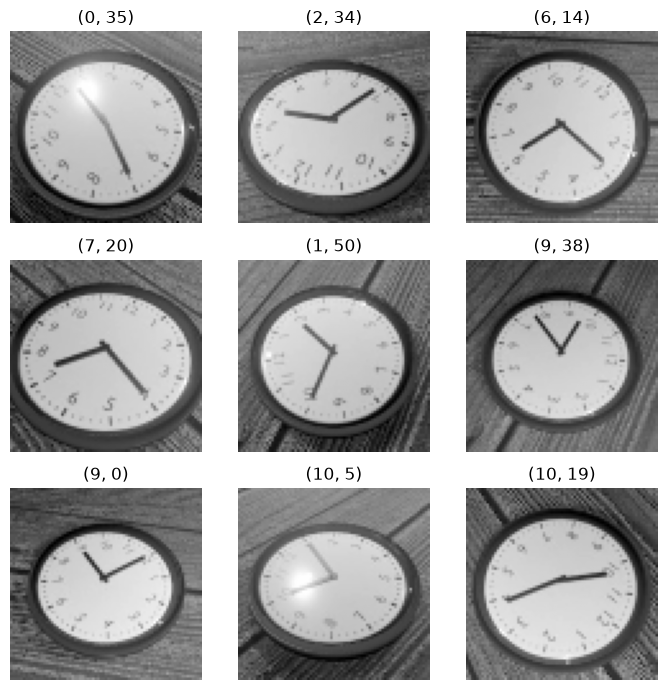

In [4]:
idxs = torch.randperm(len(x))[:9]   # 9 random images

fig, ax = plt.subplots(3, 3, figsize=(7, 7))
for k, idx in enumerate(idxs): # idx is the actual clock/label pair we visualize, k is the index of the subplots we are fitting in the 3x3
    hour, minute = y[idx].tolist()
    ax[k // 3, k % 3].imshow(x[idx, 0], cmap="gray") # k// 3 and k %3 to properly index the 3x3 grid of subplots
    ax[k // 3, k % 3].axis("off")
    ax[k // 3, k % 3].set_title(f"({hour}, {minute})")
plt.tight_layout()
plt.show()

**Dataloader**

We again create the dataloaders. Shuffling is set to true for the training set again to make sure that the batches are random between epochs. For validation and test set since we take the average the order doesn't matter and as such we don't need to shuffle. 

We take the same batch size of Task 1. With 14,400 training images this amounts to 225 updates per epoch. 
We keep the batch size to a moderate 64 to account for the fact that the images, especially in the final run are much larger compared to task 1 (150x150 as opposed to 28x28) and as such take up more space in the memory.

In [5]:
batch_size = 64

clock_train_loader = DataLoader(clock_train, batch_size = batch_size, shuffle = True)
clock_validation_loader = DataLoader(clock_validation, batch_size = batch_size, shuffle = False)
clock_test_loader = DataLoader(clock_test, batch_size = batch_size, shuffle = False)

In [6]:
print(f"Number of batches in the training DataLoader: {len(clock_train_loader)}")
print(f"Number of batches in the validation DataLoader: {len(clock_validation_loader)}")
print(f"Number of batches in the test DataLoader: {len(clock_test_loader)}")
images, labels = next(iter(clock_train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Pixel range:", images.min().item(), images.max().item())

Number of batches in the training DataLoader: 225
Number of batches in the validation DataLoader: 29
Number of batches in the test DataLoader: 29
Image batch shape: torch.Size([64, 1, 75, 75])
Label batch shape: torch.Size([64, 2])
Image data type: torch.float32
Pixel range: -2.3837831020355225 1.8514466285705566


### Evaluation metric: common-sense error

Every time is converted to *minutes since 12:00* (0 to 719). The error is the shorter way around the 12-hour clock, so 11:55 vs 0:05 is 10 minutes, not 11 h 50 min.

In [ ]:
def time_in_minutes(labels):
    """Convert (hour, minute) labels into minutes since 12:00, in [0, 720). Hour 12 and hour 0 are the same."""
    return (labels[:, 0] % 12) * 60 + labels[:, 1]

def common_sense_error(pred_minutes, true_minutes):
    """Absolute time difference in minutes, taking the 12-hour wrap-around into account."""
    diff = torch.remainder(pred_minutes - true_minutes, 720)     # in [0, 720), also for negative predictions
    return torch.minimum(diff, 720 - diff)                        # the shorter way around the clock

### Model Building

In [ ]:
class ClockNet(nn.Module):
    def __init__(self,
            output_type = "regression",     # "classification", "regression", "multihead" or "trig"
            n_classes = 24,                 # classification only: 24 -> 30-minute bins, ..., 720 -> 1-minute bins
            minute_mode = "class",          # multihead only: minute head with 60 classes ("class") or one value ("reg")
            cnn_channels = [32, 64, 128, 256],   # output channels of each convolutional block
            kernel_size = 3,                # padding = kernel_size // 2 keeps the image size, so use odd sizes
            batch_norm = True,
            hidden_dims = [256],            # fully connected layers shared by all heads
            activation = nn.ReLU,
            dropout = 0.0):
        super().__init__()
        self.output_type = output_type

        #---------------Shared convolutional backbone---------------
        layers = []
        in_ch = 1                           # grayscale images
        for out_ch in cnn_channels:
            layers.append(nn.Conv2d(in_ch, out_ch, kernel_size, padding = kernel_size // 2))
            if batch_norm:
                # Batch normalization: normalizes each channel of the conv output (zero mean, unit variance over the batch),
                # then rescales it with learnable parameters. It keeps activations on a stable scale between layers. This ultimately
                # speeds up training and makes it less sensitive to the learning rate and initialization.
                layers.append(nn.BatchNorm2d(out_ch))
            layers.append(activation())
            layers.append(nn.MaxPool2d(2))
            in_ch = out_ch
        self.features = nn.Sequential(*layers)

        # Fixed 4x4 feature map before the linear layers, so the same network accepts 75x75 and 150x150 images.
        # We keep a 4x4 map instead of one average per channel (1x1), because the position of the clock hands carries the information.
        self.pool = nn.AdaptiveAvgPool2d(4)

        #---------------Shared fully connected layers---------------
        fc_layers = [nn.Flatten()]
        input_size = cnn_channels[-1] * 4 * 4
        for hidden_size in hidden_dims:
            fc_layers.append(nn.Linear(input_size, hidden_size))
            fc_layers.append(activation())
            if dropout > 0:
                fc_layers.append(nn.Dropout(dropout))
            input_size = hidden_size
        self.fc = nn.Sequential(*fc_layers)

        #---------------Output head(s): no activation, they output logits / raw values---------------
        if output_type == "classification":
            self.head = nn.Linear(input_size, n_classes)
        elif output_type == "regression":
            self.head = nn.Linear(input_size, 1)
        elif output_type == "trig":
            self.head = nn.Linear(input_size, 4)        # sin / cos of the hour angle and of the minute angle
        elif output_type == "multihead":
            self.hour_head = nn.Linear(input_size, 12)
            self.minute_head = nn.Linear(input_size, 60 if minute_mode == "class" else 1)
        else:
            raise ValueError(f"Unknown output_type: {output_type!r}")

    def forward(self, x):
        z = self.fc(self.pool(self.features(x)))        # representation shared by all heads
        if self.output_type == "multihead":
            return self.hour_head(z), self.minute_head(z)       # out_hour, out_minute = model(x)
        out = self.head(z)
        if self.output_type == "trig":
            # Scale each (sin, cos) pair to length 1: the prediction is then a point on the unit circle.
            # (No ReLU / sigmoid: sin and cos can be negative.)
            out = torch.cat([F.normalize(out[:, :2], dim = 1), F.normalize(out[:, 2:], dim = 1)], dim = 1)
        return out